# CAD export of lens systems

A lens design ends as a prescription: radii, thicknesses, glasses, aspheric
coefficients and clear apertures. The mechanical designer needs solids:
lenses with a rim that is larger than the clear aperture so that a mount
can hold them, surfaces that go on to that rim in a way the optical shop
can polish, protective bevels on the edges,
and the ray bundle to check that the barrel, the spacers and the stop do
not clip the light. This notebook turns `raytrace.System` objects into such
a model with `pyoptics.cad` and writes it to STEP, the exchange format every
CAD system reads.

`pyoptics.cad` builds on [build123d](https://github.com/gumyr/build123d),
a Python front end to the OpenCascade kernel (``pip install pyoptics[cad]``).
The model is a boundary representation: spheres and planes are exact
surfaces in the STEP file, aspheres, toroids and freeforms are B-splines
fitted to the sag within a set tolerance.

1. A cemented achromat: lens solids, rims and bevels, the STEP file
2. What happens between clear aperture and rim
3. A Cooke triplet in a barrel with retaining rings, spacers and a stop
4. Freeforms, tilted elements and a fold mirror
5. A Fresnel lens
6. A lithography lens with 21 elements in 3D
7. Toric and cylindrical lenses
8. Off-axis mirror systems: substrates cut to the used area

In [1]:
import io
import os
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import cad
from pyoptics import off_axis as oa
from pyoptics.fresnel import FresnelSurface
from IPython.display import Image, display

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
OUT = tempfile.mkdtemp()
t_start = time.time()

## 1. A cemented achromat

A 100 mm achromat of the common 1 inch size: a biconvex crown lens
(n = 1.5168) cemented to a meniscus of dense flint (n = 1.6727), clear
aperture 23 mm, rim diameter 25.4 mm. `System.elements()` sees the
cemented pair as one element; in CAD it becomes two solids, `L1a` and
`L1b`, that touch along the cemented surface.

`Mechanics` holds the mechanical data of an element: here a rim 1.2 mm
outside the clear aperture and 0.3 mm bevels. Between the clear aperture
and the rim the spheres simply go on (the default, see section 2): a lens
is polished as a whole, so the surface that the shop makes runs out to
the bevel.
The bevels only go on edges that face air; a bevel on the cemented
interface would leave a groove for the cement.

efl 100.13 mm, elements [(1, 3)]


built in 1.43 s
L1a:  1243.4 mm³, valid True, faces ['CONE', 'CYLINDER', 'SPHERE']
L1b:  1556.9 mm³, valid True, faces ['CONE', 'CYLINDER', 'SPHERE']


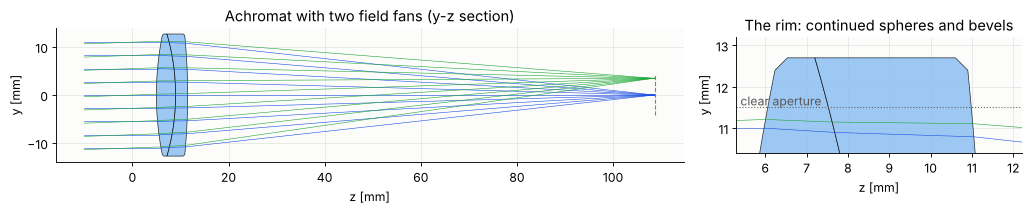

In [2]:
achromat = rt.System([rt.Surface(np.inf, 5.0, semi_diameter=11.0),
                      rt.Surface(62.8, 4.0, n_after=1.5168, semi_diameter=11.5),
                      rt.Surface(-45.7, 2.5, n_after=1.6727, semi_diameter=11.5),
                      rt.Surface(-128.2, 95.0, n_after=1.0, semi_diameter=11.5)],
                     0, 550e-6, field_angle=np.radians(2.0)).at_paraxial_focus()
print("efl {:.2f} mm, elements {}".format(achromat.paraxial().efl, achromat.elements()))

t = time.time()
model = cad.system_model(achromat, n_rays=9, ray_start=10.0,
                         mechanics=cad.Mechanics(margin=1.2, bevel=0.3))
print("built in {:.2f} s".format(time.time() - t))
for lens in model.lenses:
    kinds = sorted({f.geom_type.name for f in lens.faces()})
    print("{}: {:7.1f} mm³, valid {}, faces {}".format(lens.label, lens.volume, lens.is_valid, kinds))

fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.2, 1]})
cad.plot_section(model, axs[0])
axs[0].set_title("Achromat with two field fans (y-z section)")
cad.plot_section(model, axs[1])
axs[1].set_xlim(5.3, 12.2)
axs[1].set_ylim(10.4, 13.2)
axs[1].axhline(11.5, color="0.4", ls=":", lw=1)
axs[1].text(5.4, 11.55, "clear aperture", color="0.35")
axs[1].set_title("The rim: continued spheres and bevels")
fig.tight_layout()

The optical faces are `SPHERE` surfaces, the rim a `CYLINDER` and the
bevels `CONE`s: nothing is tessellated, so the CAD system measures the
same radii as the prescription. The solid of the crown lens can be checked
against an integral over its section: the volume between the two spheres
out to the rim, minus the ring that the front bevel cuts off between its
45° cone and the sphere.

In [3]:
def sag(R, r):
    return R - np.sign(R)*np.sqrt(R**2 - r**2)

rc, rm, b = 11.5, 12.7, 0.3
r = np.linspace(0, rm, 20001)
thick = 4.0 + sag(-45.7, r) - sag(62.8, r)
z_b = sag(62.8, rm - b)          # the front sphere ends at rm - b, the cone runs to the rim
cut = np.clip(z_b + (r - (rm - b)) - sag(62.8, r), 0, None)*(r >= rm - b)
V = np.trapezoid(2*np.pi*r*(thick - cut), r)
print("L1a: CAD {:.4f} mm³, integral {:.4f} mm³".format(model.lenses[0].volume, V))

L1a: CAD 1243.3815 mm³, integral 1243.3815 mm³


`export_step()` writes the model as one assembly: `lenses`, `rays` (one
polyline per ray, coloured by field) and the image plane, all in
millimetres whatever the units of the system. With `rays="tube"` the rays
become thin cylinders instead, which show up in renderings and can take
part in interference checks; `pupil` picks the rays (a meridional fan
`"y"`, `"x"`, both, a `"ring"` at the rim of the pupil or explicit
coordinates).

In [4]:
path = os.path.join(OUT, "achromat.step")
cad.export_step(model, path)
tubes = cad.system_model(achromat, n_rays=12, pupil="ring", rays="tube", ray_radius=0.05,
                         mechanics=cad.Mechanics(margin=1.2, bevel=0.3))
path_tubes = os.path.join(OUT, "achromat_tubes.step")
cad.export_step(tubes, path_tubes)
for p in (path, path_tubes):
    print("{}: {:.0f} kB".format(os.path.basename(p), os.path.getsize(p)/1e3))

achromat.step: 123 kB
achromat_tubes.step: 1140 kB


## 2. Between clear aperture and rim

The clear aperture is what the optics needs; the rim is what the mount
needs. `Mechanics` sets the rim semi-diameter directly (`semi_diameter`) or
as a `margin` over the largest clear semi-diameter of the element, and
`land` decides what fills the annulus between them:

- `"continue"` (the default): the surface goes on in a way that is
  polished together with the optical surface. A sphere stays the same
  sphere, a toroid the same toroid (section 7), and an asphere goes on as
  its **best fit sphere**, the sphere through the vertex and the rim of the
  clear aperture, where it joins the asphere. A flat annulus next to a
  curved surface cannot be polished in the same run, and an asphere would
  only make the outer zone harder to polish for nothing. Only Fresnel
  surfaces (molded) and a sphere that is smaller than the rim (a steep
  face with a small clear aperture on a large element) get a flat land.
- `"flat"`: a plane perpendicular to the axis at the height of the clear
  aperture rim, a seat for a retaining ring or a spacer on molded or
  diamond turned parts.
- `"extend"`: the optical surface itself, aspheres included, up to the
  rim.

The edges at the rim are the ones that chip, so the bevels go there. A
lens whose surfaces would cross before the rim (a strong biconvex lens
with a large margin) cannot be built; `system_model()` refuses it with the
edge thickness that it found. With flat lands the same lens can have a
rim of any size.

land = 'continue' with a 4 mm margin: Edge thickness -1.93 below 0.1 at semi-diameter 13.0
land = 'flat' with a 4 mm margin: fine


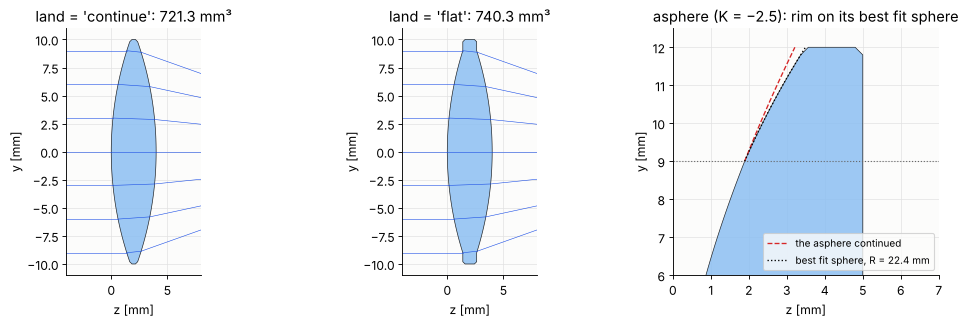

In [5]:
lens = rt.System([rt.Surface(30.0, 4.0, n_after=1.5168, semi_diameter=9.0),
                  rt.Surface(-30.0, 40.0, n_after=1.0, semi_diameter=9.0)], 0, 550e-6)
asphere = rt.Surface(20.0, 5.0, n_after=1.5168, conic=-2.5, semi_diameter=9.0)
asph = rt.System([asphere, rt.Surface(np.inf, 40.0, n_after=1.0, semi_diameter=9.0)], 0, 550e-6)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, land in zip(axs[:2], ["continue", "flat"]):
    m = cad.system_model(lens, n_rays=7, ray_start=4, image_plane=False,
                         mechanics=cad.Mechanics(margin=1.0, land=land, bevel=0.2))
    cad.plot_section(m, ax)
    ax.set_xlim(-4, 8)
    ax.set_ylim(-11, 11)
    ax.set_title("land = {!r}: {:.1f} mm³".format(land, m.lenses[0].volume))
for land in ("continue", "flat"):
    try:
        cad.system_model(lens, rays=None, mechanics=cad.Mechanics(margin=4.0, land=land))
        print("land = {!r} with a 4 mm margin: fine".format(land))
    except ValueError as err:
        print("land = {!r} with a 4 mm margin:".format(land), str(err).split(" between")[0])
m = cad.system_model(asph, n_rays=7, ray_start=4, image_plane=False,
                     mechanics=cad.Mechanics(margin=3.0, bevel=0.2))
cad.plot_section(m, axs[2], rays=False)
r = np.linspace(9.0, 12.0, 100)
z9 = asphere.sag(np.array([81.0]))[0]
R_bfs = (81 + z9**2)/(2*z9)
axs[2].plot(asphere.sag(r**2), r, color="C3", ls="--", lw=1.2, label="the asphere continued")
axs[2].plot(R_bfs - np.sqrt(R_bfs**2 - r**2), r, color="k", ls=":", lw=1.2,
            label="best fit sphere, R = {:.1f} mm".format(R_bfs))
axs[2].axhline(9.0, color="0.4", ls=":", lw=1)
axs[2].set_xlim(0, 7)
axs[2].set_ylim(6, 12.5)
axs[2].legend(loc="lower right", fontsize=9)
axs[2].set_title("asphere (K = −2.5): rim on its best fit sphere")
fig.tight_layout()

## 3. A Cooke triplet in a barrel

With `mount=cad.Mount()` the model gets a first cut of the mechanics of a
coaxial lens: a barrel whose bore is the largest rim plus a radial
clearance, a retaining ring in front of the first and behind the last
element, spacers between the elements and an aperture plate at a stop that
lies in air. The rings and spacers are built as solids of revolution and
then cut by the lens solids, so they sit exactly on the rims and bevels.
Their bore starts a little outside the clear aperture of the lens they
touch (`spacer_clearance`) and runs conically from one lens to the next:
the edge of a bundle of straight rays between two surfaces is a convex
function of z and stays inside that cone.

The triplet is the classic f/4.5 Cooke design (efl about 47 mm, ±10°),
whose stop sits in the air space between the negative lens and the rear
crown. Its positive lenses are thin at the edge already: with continued
spheres a rim 1 mm outside the clear aperture is about what they allow.

built in 0.53 s
part        volume [mm³]
L1              213.8
L2              197.9
L3              203.3
barrel         2176.8
ring_front      110.3
spacer_1        435.8
spacer_2a       194.5
spacer_2b       359.0
ring_back       265.5
stop             37.1


largest overlap of mount and lenses: 0.0e+00 mm³
closest approach of a ring or spacer to a traced ray: 0.66 mm


True

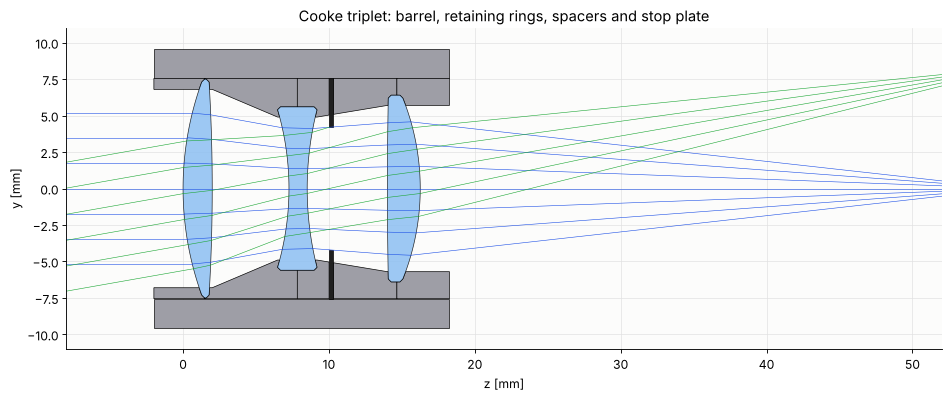

In [6]:
triplet = rt.System([rt.Surface(21.48, 2.0, n_after=1.6204, semi_diameter=6.5),
                     rt.Surface(-124.1, 5.26, n_after=1.0, semi_diameter=6.5),
                     rt.Surface(-19.1, 1.25, n_after=1.6034, semi_diameter=4.6),
                     rt.Surface(22.0, 1.5, n_after=1.0, semi_diameter=4.6),
                     rt.Surface(np.inf, 4.0, semi_diameter=4.2),
                     rt.Surface(328.9, 2.25, n_after=1.6204, semi_diameter=5.4),
                     rt.Surface(-16.7, 43.0, n_after=1.0, semi_diameter=5.4)],
                    4, 550e-6, field_angle=np.radians(10)).at_paraxial_focus()
t = time.time()
cooke = cad.system_model(triplet, n_rays=7, ray_start=8, mechanics=cad.Mechanics(margin=1.0, bevel=0.2),
                         mount=cad.Mount(wall=2.0, ring_length=2.0, spacer_clearance=0.3))
print("built in {:.2f} s".format(time.time() - t))
print("part        volume [mm³]")
for part in cooke.lenses + cooke.mount:
    print("{:10s} {:10.1f}".format(part.label, part.volume))

clash = max((p & l).volume if (p & l) is not None else 0.0 for p in cooke.mount for l in cooke.lenses)
gap = min(p.distance_to(r) for p in cooke.mount if p.label not in ("barrel", "stop") for r in cooke.rays)
print("largest overlap of mount and lenses: {:.1e} mm³".format(clash))
print("closest approach of a ring or spacer to a traced ray: {:.2f} mm".format(gap))

fig, ax = plt.subplots(figsize=(12, 5))
cad.plot_section(cooke, ax)
ax.set_xlim(-8, 52)
ax.set_title("Cooke triplet: barrel, retaining rings, spacers and stop plate")
fig.tight_layout()
cad.export_step(cooke, os.path.join(OUT, "cooke_triplet.step"))

The negative lens has the smallest rim, so it sits in the bore with a
radial gap; the spacers on both sides reach around its rim and centre it.
In a real barrel the bore would step down to each lens with a fit, and the
retaining rings would be threaded; the generated parts are a starting
point that already has the right axial positions and contact faces.

## 4. Freeforms, tilted elements and a fold mirror

Not every slab is a solid of revolution. Surfaces with a `sag_xy(x, y)`
(`ZernikeSurface`, `qaspheres.Q2DSurface`, `freeform.TabulatedSurface`) and
slabs whose surfaces are tilted or decentred against each other are cut
from a cylinder along the axis of their first surface: by a B-spline face
through the sag on a grid, or by the revolved section of a rotationally
symmetric surface. Rims and bevels work as before: a freeform goes on as
itself up to the rim. With `land="flat"` the rim height of a freeform
changes around the circumference, so the flat land is put at the point of
the rim that lies farthest towards air, and a short step joins it to the
optical face.

The example has a plate with a Zernike astigmatism and trefoil departure,
a window tilted by 8° and a fold mirror with a freeform figure on a
coordinate break of 45°. The mirror gets a substrate with a flat back
`mirror_thickness` behind its face.

built in 0.55 s
L1:   845.3 mm³, faces ['BSPLINE', 'CONE', 'CYLINDER', 'PLANE']
L2:   396.2 mm³, faces ['CONE', 'CYLINDER', 'PLANE']
M3:  1258.7 mm³, faces ['BSPLINE', 'CYLINDER', 'PLANE']


True

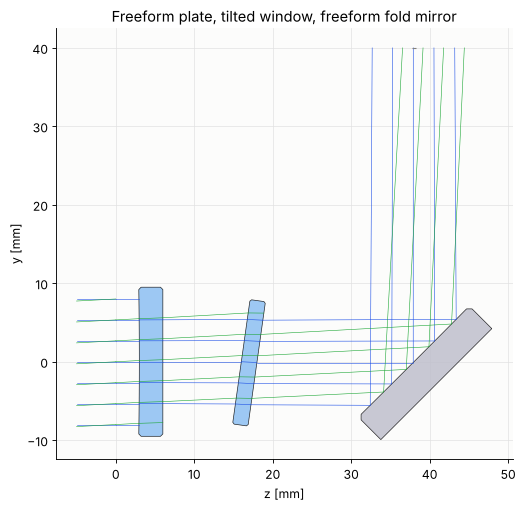

In [7]:
fold = rt.System([rt.Surface(np.inf, 3.0, semi_diameter=8.0),
                  rt.ZernikeSurface(np.inf, 3.0, zernike={5: 0.05, 10: 0.03}, norm_radius=8.0,
                                    n_after=1.5168, semi_diameter=8.0),
                  rt.Surface(np.inf, 10.0, n_after=1.0, semi_diameter=8.0),
                  rt.Surface(np.inf, 2.0, n_after=1.5168, semi_diameter=7.0, tilt=(np.radians(8), 0, 0)),
                  rt.Surface(np.inf, 20.0, n_after=1.0, semi_diameter=7.0, tilt=(np.radians(8), 0, 0)),
                  rt.CoordinateBreak(tilt=(np.pi/4, 0, 0)),
                  rt.ZernikeSurface(np.inf, 0.0, zernike={5: 0.02}, norm_radius=8.0, mirror=True,
                                    semi_diameter=8.0),
                  rt.CoordinateBreak(tilt=(np.pi/4, 0, 0), thickness=-40.0)],
                 0, 550e-6, field_angle=np.radians(3.0))
t = time.time()
folded = cad.system_model(fold, n_rays=7, ray_start=5,
                          mechanics={0: cad.Mechanics(margin=1.5, bevel=0.3),
                                     1: cad.Mechanics(margin=1.0, bevel=0.2),
                                     2: cad.Mechanics(margin=2.0, mirror_thickness=4.0, bevel=0.5)})
print("built in {:.2f} s".format(time.time() - t))
for part in folded.lenses:
    print("{}: {:7.1f} mm³, faces {}".format(part.label, part.volume,
                                            sorted({f.geom_type.name for f in part.faces()})))
fig, ax = plt.subplots(figsize=(8, 6.5))
cad.plot_section(folded, ax)
ax.set_title("Freeform plate, tilted window, freeform fold mirror")
fig.tight_layout()
cad.export_step(folded, os.path.join(OUT, "fold.step"))

The trefoil term of the plate bends the rays out of the meridional plane,
so the section shows their projection. The Zernike terms average to zero
over every circle, so the plate, continued to its rim, has the volume of a
3 mm disk of radius 9.5 mm minus what the bevels remove; the tests of
`pyoptics.cad` check this and the flat lands against integrals over the
sag.

## 5. A Fresnel lens

A `fresnel.FresnelSurface` (notebook [421 (Fresnel lenses)](421_fresnel_lenses.ipynb))
has a stepped section: facets that follow the parent surface and risers
between them. The CAD section uses its `section()` with a B-spline per
facet and straight risers, so the facets keep their curvature and the
risers their draft angle. A Fresnel lens is molded, not
polished: its rim is a flat land at the height of the last facet.

24 faces, 699.5 mm³


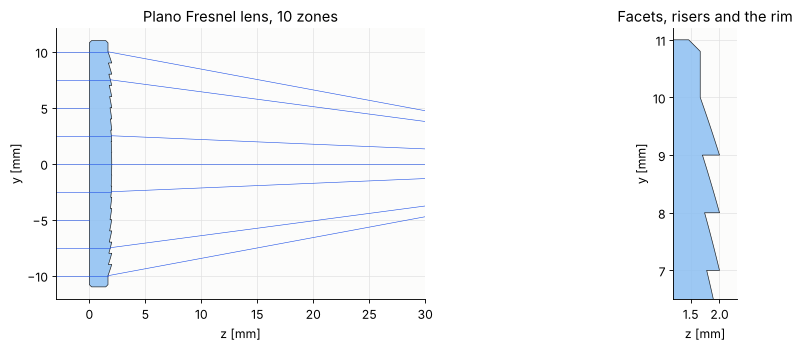

In [8]:
fresnel = FresnelSurface(-30.0, n_zones=10, radius=10.0, n_after=1.0, semi_diameter=10.0,
                         thickness=60.0)
fl = rt.System([rt.Surface(np.inf, 2.0, n_after=1.5, semi_diameter=10.0), fresnel], 0, 550e-6)
fm = cad.system_model(fl, n_rays=9, ray_start=3, image_plane=False,
                      mechanics=cad.Mechanics(margin=1.0, bevel=0.2))
print("{} faces, {:.1f} mm³".format(len(fm.lenses[0].faces()), fm.lenses[0].volume))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 1]})
cad.plot_section(fm, axs[0])
axs[0].set_xlim(-3, 30)
axs[0].set_title("Plano Fresnel lens, 10 zones")
cad.plot_section(fm, axs[1], rays=False)
axs[1].set_xlim(1.2, 2.3)
axs[1].set_ylim(6.5, 11.2)
axs[1].set_title("Facets, risers and the rim")
fig.tight_layout()

## 6. A lithography lens with 21 elements in 3D

The all fused silica KrF projection lens by J. B. Caldwell
(`raytrace.caldwell_krf_lens()`, the lens of notebook
[401 (Seidel aberrations)](401_seidel_caldwell_lens.ipynb)) images a
reticle 4× reduced at NA 0.56 over 1 m from object to image. Each of its
21 singlets gets a rim 3 mm outside its clear aperture and 0.5 mm bevels,
with every surface continued to the rim, except the steep concave back of
the thick meniscus in front of the last two lenses (R = 75.7 mm on a rim
of 82.3 mm), which gets a flat land; the rays leave the reticle at the axis, 70 % and the full
field. The section shows the rims and bevels of all lenses at once,
`plot_3d()` the tessellated solids as build123d hands them to the STEP and
glTF writers.

21 lenses built in 0.4 s
fused silica: 10732 cm³, 23.6 kg


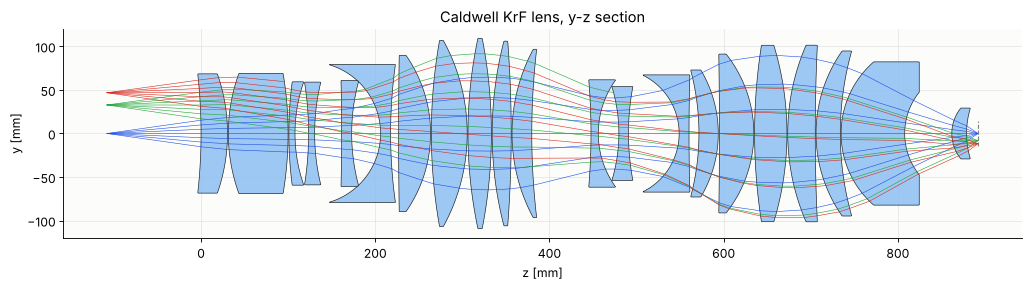

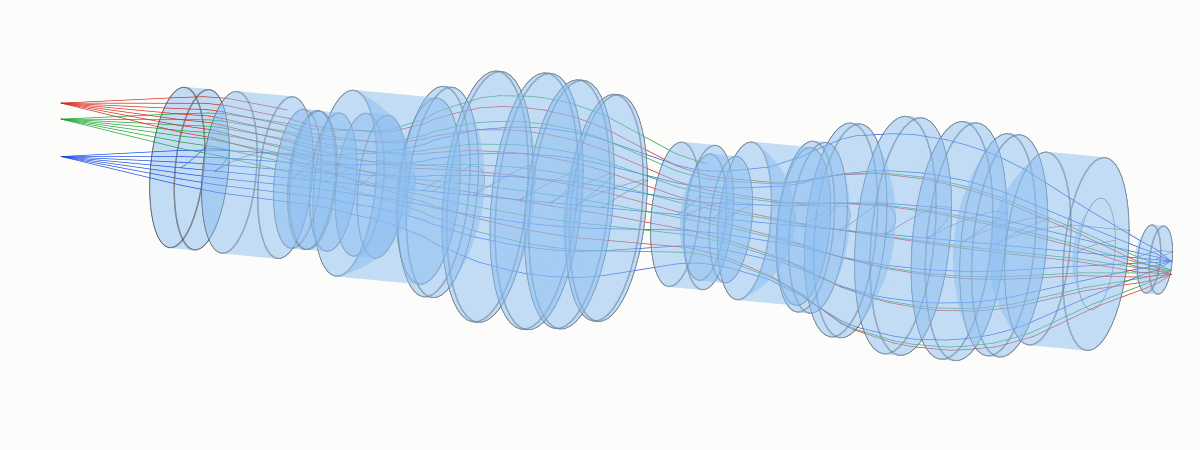

caldwell.step: 771 kB
caldwell.glb: 648 kB


In [9]:
caldwell = rt.caldwell_krf_lens()
t = time.time()
litho = cad.system_model(caldwell, fields=[0.0, 0.7*caldwell.max_field, caldwell.max_field],
                         n_rays=7, ray_start=0, mechanics=cad.Mechanics(margin=3.0, bevel=0.5))
print("{} lenses built in {:.1f} s".format(len(litho.lenses), time.time() - t))
glass = sum(lens.volume for lens in litho.lenses)
print("fused silica: {:.0f} cm³, {:.1f} kg".format(glass/1e3, 2.201e-6*glass))

fig, ax = plt.subplots(figsize=(13, 4.2))
cad.plot_section(litho, ax)
ax.set_title("Caldwell KrF lens, y-z section")
fig.tight_layout()
plt.show()

# matplotlib fits the 3D box into a square: a square axes as wide as the
# figure, of which the figure shows the middle band
fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_axes([0, 0.5 - 12/4.5/2, 1, 12/4.5], projection="3d")
cad.plot_3d(litho, ax, elev=15, azim=-70)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100)  # without the inline backend's tight box
plt.close(fig)
display(Image(buf.getvalue()))

for name, writer in [("caldwell.step", cad.export_step), ("caldwell.glb", cad.export_gltf)]:
    path = os.path.join(OUT, name)
    writer(litho, path)
    print("{}: {:.0f} kB".format(name, os.path.getsize(path)/1e3))

The glTF file (`export_gltf()`) is what web viewers and three.js load; it
holds the tessellated lenses with their names and colours, the STEP file
the exact geometry for the CAD system.

## 7. Toric and cylindrical lenses

`raytrace.ToroidalSurface` (a curve in the y-z plane rotated about an axis
parallel to y, so that the x-z section is a circle of radius R_x) and
`raytrace.BiconicSurface` (conic sections of different curvature in x and
y) are surfaces with a `sag_xy`, cut from the cylinder of the rim by a
B-spline face. With `land="continue"` the torus goes on as the same torus
to the rim: a toric surface is generated and polished as a whole on a
toric lap, like a sphere on a spherical one.

The first lens is the toric spectacle lens that notebook
[435 (progressive spectacle lenses)](435_progressive_lenses.ipynb) optimizes for an
astigmatic eye: a +4 D spherical front, a toric back with R = 77.58 mm and
R_x = 112.20 mm rotated by 20° about the axis (a cylinder of −1.98 D at
20°), 2 mm centre thickness, here as an uncut round blank of 52 mm
before it is edged to the frame. The second is a plano-convex cylinder
lens with f = 50 mm in y and no power in x (R_x = ∞), which turns a
parallel beam into a line focus along x.

built in 0.47 s
spectacle lens: 5297.1 mm³, valid True, faces ['BSPLINE', 'CYLINDER', 'SPHERE']
cylinder lens: 1290.0 mm³, valid True, faces ['BSPLINE', 'CONE', 'CYLINDER', 'PLANE']
edge thickness of the blank: 3.74 mm at 110°, 2.31 mm at 20°
volume: CAD 5297.1 mm³, integral 5296.6 mm³


largest distance of the torus from the CAD face: 0.63 nm


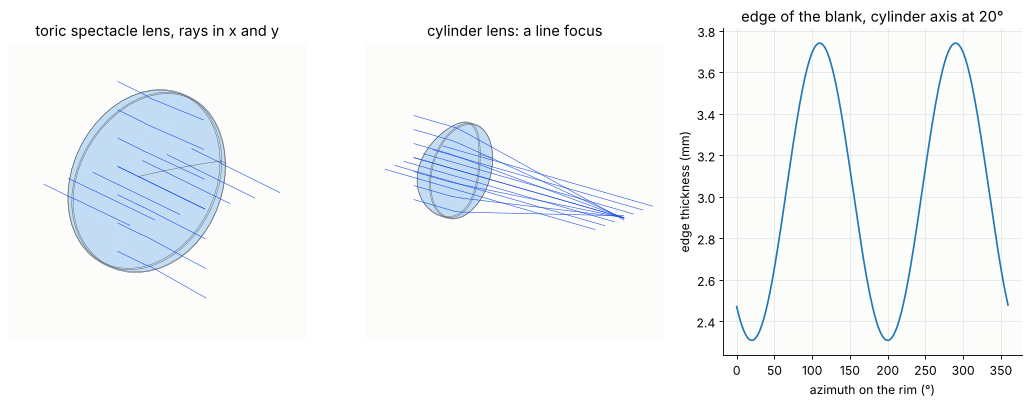

In [10]:
# the toric spectacle lens of notebook 435 (progressive spectacle lenses), section 8, as an uncut blank
toric_back = rt.ToroidalSurface(77.58, 30.0, R_x=112.20, n_after=1.0, semi_diameter=25.0,
                                tilt=(0.0, 0.0, np.radians(20.0)))
spectacle = rt.System([rt.Surface(124.5, 2.0, n_after=1.498, semi_diameter=25.0), toric_back],
                      0, 555e-6)
# a plano-convex cylinder lens, f = 50 mm in y, no power in x
cylinder = rt.System([rt.ToroidalSurface(25.84, 4.0, R_x=np.inf, n_after=1.5168,
                                         semi_diameter=10.0),
                      rt.Surface(np.inf, 47.4, n_after=1.0, semi_diameter=10.0)], 0, 550e-6)
t = time.time()
spec = cad.system_model(spectacle, n_rays=7, pupil="xy", ray_start=10.0, image_plane=False,
                        mechanics=cad.Mechanics(margin=1.0, bevel=0.3))
cyl = cad.system_model(cylinder, n_rays=7, pupil="xy", ray_start=10.0,
                       mechanics=cad.Mechanics(margin=1.0, bevel=0.2))
print("built in {:.2f} s".format(time.time() - t))
for name, m in (("spectacle lens", spec), ("cylinder lens", cyl)):
    lens = m.lenses[0]
    print("{}: {:.1f} mm³, valid {}, faces {}".format(name, lens.volume, lens.is_valid,
                                                     sorted({f.geom_type.name for f in lens.faces()})))

# edge thickness around the rim and the volume from the sag (without the bevels)
phi = np.linspace(0, 2*np.pi, 721)[:-1]            # azimuth in the lens
loc = phi - toric_back.tilt[2]                       # in the frame of the torus
rm, b = 26.0, 0.3
edge = 2.0 + toric_back.sag_xy(rm*np.cos(loc), rm*np.sin(loc)) - spectacle.surfaces[0].sag(rm**2)
print("edge thickness of the blank: {:.2f} mm at {:.0f}°, {:.2f} mm at {:.0f}°".format(
    edge.max(), np.degrees(phi[edge.argmax()]) % 180, edge.min(), np.degrees(phi[edge.argmin()]) % 180))
r = np.linspace(0, rm, 1301)
Rg, Pg = np.meshgrid(r, phi)
thick = 2.0 + toric_back.sag_xy(Rg*np.cos(Pg), Rg*np.sin(Pg)) - spectacle.surfaces[0].sag(Rg**2)
V = np.trapezoid(np.mean(thick, axis=0)*2*np.pi*r, r) - 2*2*np.pi*(rm - b/3)*b**2/2
print("volume: CAD {:.1f} mm³, integral {:.1f} mm³".format(spec.lenses[0].volume, V))
import build123d as bd
x, y = np.meshgrid(np.linspace(-25, 25, 21), np.linspace(-25, 25, 21))
inside = np.hypot(x, y) < 25.5                   # inside the bevel
o, R = spectacle.frames()[0][1]
face = max((f for f in spec.lenses[0].faces() if f.geom_type.name == "BSPLINE"),
           key=lambda f: f.area)                    # the toric face
dev = [face.distance_to(bd.Vector(*(o + R @ [xx, yy, toric_back.sag_xy(xx, yy)])))
       for xx, yy in zip(x[inside], y[inside])]
print("largest distance of the torus from the CAD face: {:.2g} nm".format(1e6*max(dev)))

fig = plt.figure(figsize=(13, 5.2))
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
cad.plot_3d(spec, ax1, elev=20, azim=-35)
ax1.set_title("toric spectacle lens, rays in x and y")
ax2 = fig.add_subplot(1, 3, 2, projection="3d")
cad.plot_3d(cyl, ax2, elev=20, azim=-50)
ax2.set_title("cylinder lens: a line focus")
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(np.degrees(phi), edge, color="C0")
ax3.set_xlabel("azimuth on the rim (°)")
ax3.set_ylabel("edge thickness (mm)")
ax3.set_title("edge of the blank, cylinder axis at 20°")
fig.tight_layout()
for name, m in (("toric_spectacle_lens.step", spec), ("cylinder_lens.step", cyl)):
    cad.export_step(m, os.path.join(OUT, name))

The edge of the toric blank is thinnest in the meridian of the cylinder
axis (20°, the weaker back curvature) and thickest at right angles to it
(110°); a minus cylinder lens always has this edge with two thick and two
thin sides, and the frame shape decides how much of it is left after
edging. The B-spline face of the CAD solid follows the torus to about a
nanometre, and the volume agrees with the integral over the sag up to the
bevels.

## 8. Off-axis mirror systems

An unobscured mirror system uses off-axis parts of a coaxial parent:
the Cook three-mirror anastigmat of notebook
[436 (off-axis mirrors and nodal aberrations)](436_off_axis_mirrors_nodal_aberrations.ipynb),
an off-axis paraboloid, the mirrors of an EUV projection lens with its ring
field. A disk centred on the parent axis would be a mirror many times
larger than the light needs, and it would run through the other beams.
`Mechanics(outline=...)` cuts the substrate to the used area instead: the
footprint of the beams of all `footprint_fields` (rays on rings in the
pupil), with an outline around it grown by `margin`:

- `"circle"`, a round blank around the footprint,
- `"rectangle"`, its bounding box,
- `"hull"`, its convex hull with round corners (one smooth side wall),
- or a polygon in the local x-y plane of the mirror, taken as it is.

The substrate is a prism over the outline along the mirror normal at the
centre of the footprint (`axis="normal"`, the side walls perpendicular to
the face, as on a real off-axis blank; `axis="parent"` keeps them parallel
to the parent axis), cut in front by the mirror surface and behind by a
plane `mirror_thickness` behind the deepest point of the face. The margin
continues the parent surface itself: an off-axis segment is polished or
diamond turned as a part of its parent, so the conic or asphere goes on
as it is, unlike the rim of a coaxial lens of section 2.

The TMA below is the aperture-offset version of
notebook 436 (off-axis mirrors and nodal aberrations), F/4, 600 mm focal
length, with a 3° × 1° field centred 3° off the axis.


circle  built in 3.1 s: M1 411 cm³, M2 62 cm³, M3 60 cm³


hull    built in 2.0 s: M1 333 cm³, M2 53 cm³, M3 37 cm³


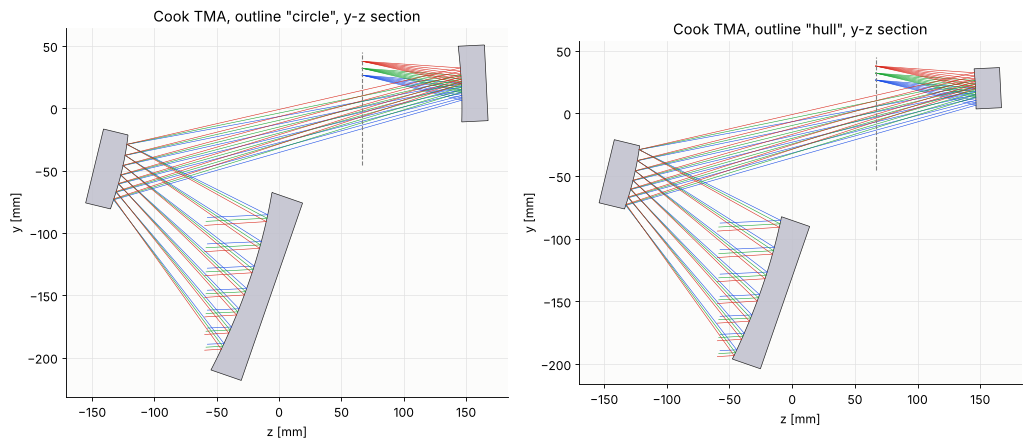

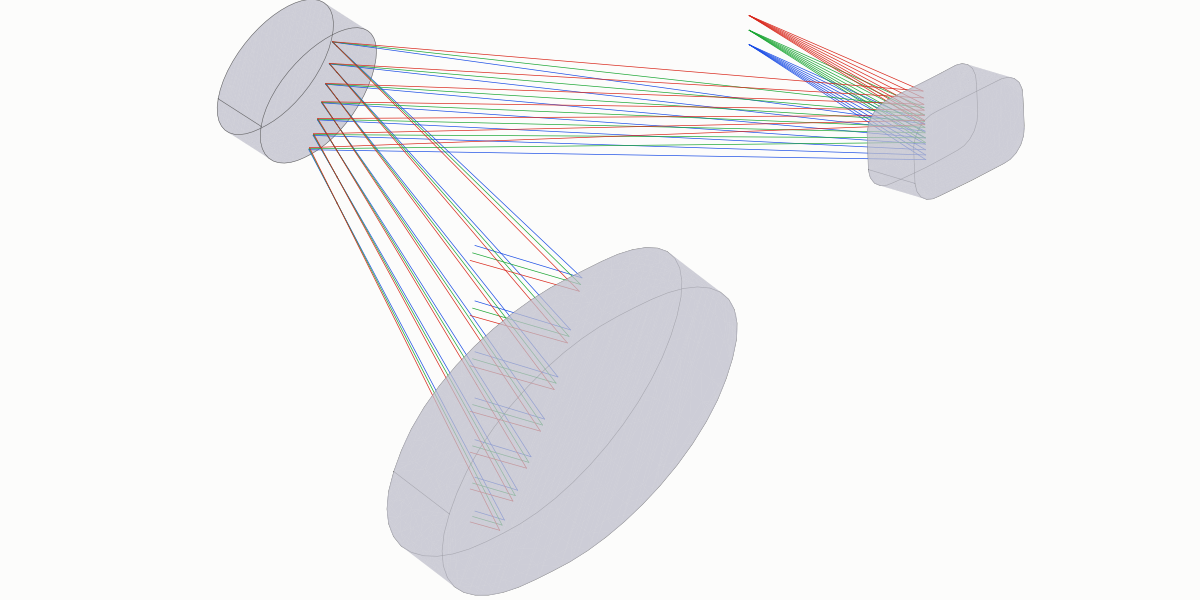

True

In [11]:
tma = oa.cook_tma(efl=600.0, f_number=4.0, field_angle=np.radians(4.0), aperture_offset=-2.0)
F_tma = oa.rectangular_field((0.0, np.radians(3.0)), np.radians([1.5, 0.5]), (3, 3))
fans = [tuple(f) for f in F_tma[[1, 4, 7]]]  # the middle column of the field
footprint = [tuple(f) for f in F_tma]       # corners, edges and centre
models = {}
for outline in ("circle", "hull"):
    t = time.time()
    models[outline] = cad.system_model(tma, fields=fans, n_rays=7, footprint_fields=footprint,
                                       mechanics=cad.Mechanics(outline=outline, margin=3.0,
                                                               mirror_thickness=20.0))
    print("{:7s} built in {:.1f} s: ".format(outline, time.time() - t)
          + ", ".join("{} {:.0f} cm³".format(m.label, m.volume/1e3)
                      for m in models[outline].lenses))

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (outline, model) in zip(ax, models.items()):
    cad.plot_section(model, a)
    a.set_title("Cook TMA, outline \"{}\", y-z section".format(outline))
fig.tight_layout()
plt.show()

fig = plt.figure(figsize=(12, 6))
ax = fig.add_axes([0, 0.5 - 12/6/2, 1, 12/6], projection="3d")
cad.plot_3d(models["hull"], ax, elev=25, azim=-50, alpha=0.5)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100)
plt.close(fig)
display(Image(buf.getvalue()))
cad.export_step(models["hull"], os.path.join(OUT, "tma.step"))


The section cuts the substrates in the meridional plane, which is the
plane of symmetry: the mirrors are segments above and below the parent
axis (z to the right), and the light clears every substrate. The circle
blanks are larger than the hulls where the footprint is elongated, on the
primary (first mirror, bottom) most of all, whose footprint is a wide
oval of the 3° field. The traced rays end on the mirror faces and no ray
runs through a substrate; the tests of `pyoptics.cad` check this, the
circle radius (footprint plus margin) and the mechanical axis against the
normal of an off-axis paraboloid.

Q-type and Zernike sags are polynomials normalized to a radius beyond
which they grow fast. The face is therefore built over the outline only,
and continued past it (where only the boolean cut sees it) with the slope
at the outline. If an outline reaches beyond where the design defines its
surface, e.g. a circle around a long footprint on a `QconQ2DSurface` whose
freeform part has a smaller radius, `system_model()` raises a ValueError;
`"rectangle"` or `"hull"` then usually fit.


## 9. Lens files: patent tables, Zemax and CODE V

Before a lens reaches the CAD system it usually comes from somewhere else:
a table in a patent or a book, or a file of a lens design program.
`lens_files` reads and writes three formats into a `Prescription` (the
surfaces with the stop, the entrance pupil diameter, the wavelengths and
the fields) that builds the `raytrace.System` at each wavelength:

- patent tables, plain text or CSV: one row per surface with R, d, n_d,
  V_d, the semi-diameter and the glass, a second table (or lines
  "K = ..., A4 = ...") with the conic constants and aspheric coefficients;
  "∞", blank cells for air, "STO" and "*" marks, "1.2×10^-5" or "1.2D-05"
  are understood,
- Zemax OpticStudio sequential files (`.zmx`), with standard and even
  aspheric, toroidal, biconic and paraxial surfaces and coordinate breaks,
- CODE V sequence files (`.seq`), with spheres, conics, aspheres, Y
  toroids, mirrors and decentres.

Glass names are looked up in the catalogues of `pyoptics.glasses`
("N-SK16", "nsk16" and "N-SK16_SCHOTT" are the same glass); a name that is
not there falls back to its n_d and V_d (`materials.abbe_dispersion()`).
The Cooke triplet of section 3, as a patent would print it, with real
glasses for its crown and flint and the d line, F and C as wavelengths:

In [12]:
from pyoptics import lens_files

table = """
# units: mm
# wavelengths [nm]: 587.5618 486.1327 656.2725
# entrance pupil diameter: 10
# field angles [deg]: 0 7 10

 Surf        r        d        nd       νd     ED/2   glass
  OBJ        ∞        ∞
   1      21.48     2.00    1.62041   60.32     6.5   N-SK16
   2     -124.1     5.26                         6.5
   3      -19.1     1.25    1.60342   38.03     4.6   F5
   4      22.00     1.50                         4.6
  STO        ∞     4.00                         4.2
   6      328.9     2.25    1.62041   60.32     5.4   N-SK16
   7      -16.7    43.00                         5.4
  IMG        ∞
"""
lens = lens_files.read_patent(table)
print(lens)
cooke = lens.system()
par = cooke.paraxial()
print("f' = {:.2f} mm, F/{:.2f}, back focal length {:.2f} mm".format(par.efl, par.f_number, par.bfl))
for s, w in zip(lens.systems(), lens.wavelengths):
    s = s.with_image_distance(par.bfl)          # the image plane of the d line
    print("{:6.1f} nm: n(N-SK16) = {:.5f}, RMS spot on axis {:5.1f} µm, at 10° {:5.1f} µm".format(
        w*1e6, s.n[1], 1e3*s.spot_diagram(0.0).rms, 1e3*s.spot_diagram(np.radians(10)).rms))

Prescription('', 7 surfaces, stop 4, wavelengths (0.0005875618, 0.0004861327, 0.0006562725) mm, fields [(0.0, 0.0), (0.0, 0.12217304763960307), (0.0, 0.17453292519943295)], epd 10.0)
f' = 47.27 mm, F/4.73, back focal length 40.86 mm
 587.6 nm: n(N-SK16) = 1.62041, RMS spot on axis  20.9 µm, at 10°  23.0 µm


 486.1 nm: n(N-SK16) = 1.62756, RMS spot on axis  26.6 µm, at 10°  25.6 µm
 656.3 nm: n(N-SK16) = 1.61727, RMS spot on axis  16.3 µm, at 10°  22.0 µm


Blank n_d and V_d cells are air; the glass column wins over n_d and V_d
when the catalogue has the glass (else they are the fallback). The three
systems of `lens.systems()` share the geometry and see the dispersion of
the catalogue glasses, so the spot sizes show the colour of the triplet.

Patents with aspheres give their coefficients in many notations. This
molded singlet (a made-up example in the style of such tables, not a
corrected design) gives them per surface, in powers of ten and with the
Fortran exponent:

In [13]:
singlet = lens_files.read_patent("""
Surface No.      R         D        Nd       νd
   1(STO)*     3.20      2.10    1.58913   61.15
   2*         -9.80      3.27
Aspheric data
1st surface  K = -0.6512, A4 = 1.25×10^-3, A6 = 2.1×10^-5
2nd surface  K = -24.0,   A4 = 4.6D-03,    A6 = -6.3D-04, A8 = 2.2D-05
""", epd=2.8, fields=[0.0, np.radians(12.0)])
for s in singlet.surfaces:
    print(s)
asph = singlet.system()
par = asph.paraxial()
print("f' = {:.3f} mm, F/{:.2f}, image {:.3f} mm behind the lens ({:.3f} mm in the table)".format(
    par.efl, par.f_number, par.bfl, asph.surfaces[-1].thickness))

Surface(R=3.2, thickness=2.1, n_after=None, material=(1.58913, 61.15), conic=-0.6512, aspheric=(0.00125, 2.1e-05), semi_diameter=None)
Surface(R=-9.8, thickness=3.27, n_after=1.0, material=None, conic=-24.0, aspheric=(0.0046, -0.00063, 2.2e-05), semi_diameter=None)
f' = 4.356 mm, F/1.56, image 3.296 mm behind the lens (3.270 mm in the table)


The writers turn a `System` (or a `Prescription`) into the same formats.
Every number is written with all its digits, so reading the file back
gives the same system: the same rays leave the triplet at the same points
(differences at the level of rounding). Catalogue glasses are written by
name, model glasses as `___BLANK` model glasses (Zemax) or glass codes
(CODE V). Decentred and tilted surfaces go to Zemax as a pair of
coordinate breaks around the surface and come back as one displaced
surface.

In [14]:
paths = {}
for ext in ("zmx", "seq", "txt"):
    paths[ext] = os.path.join(OUT, "cooke." + ext)
    lens_files.write(lens, paths[ext])
print(open(paths["seq"]).read())

px, py = np.meshgrid(np.linspace(-1, 1, 11), np.linspace(-1, 1, 11))
inside = px**2 + py**2 <= 1
for ext, path in paths.items():
    back = lens_files.read(path).system()
    worst = 0.0
    for field in np.radians([0.0, 7.0, 10.0]):
        rays = cooke.rays(field, px[inside], py[inside])
        a, b = cooke.trace(rays), back.trace(rays)
        worst = max(worst, np.max(np.abs(a.points[-1][a.valid] - b.points[-1][b.valid])))
    print("{}: largest difference of the image points {:.1e} mm".format(ext, worst))

! pyoptics lens prescription (CODE V sequence)
LEN NEW
DIM M
RDM
WL 587.5618 486.1327 656.2725
REF 1
WTW 1 1 1
EPD 10.0
YAN 0.0 7.0 10.0
SO 0.0 1e10
S 21.48 2.0 N-SK16_SCHOTT
  CIR 6.5
S -124.1 5.26
  CIR 6.5
S -19.1 1.25 F5_SCHOTT
  CIR 4.6
S 22.0 1.5
  CIR 4.6
S 0.0 4.0
  STO
  CIR 4.2
S 328.9 2.25 N-SK16_SCHOTT
  CIR 5.4
S -16.7 43.0
  CIR 5.4
SI 0.0 0.0
GO

zmx: largest difference of the image points 0.0e+00 mm
seq: largest difference of the image points 0.0e+00 mm
txt: largest difference of the image points 0.0e+00 mm


Only the structure of the files that is publicly documented and commonly
seen is used, and the tests write their own files. Not covered are
multiple configurations, solves and pickups (their current values are
read), non-circular apertures and the many other surface types of the
programs; those raise an error rather than being skipped. The tilt
conventions of the two programs are taken to be those of `raytrace`
(right-handed rotations about x, y, z in this order) and are not checked
against the programs themselves.

## Summary

- `cad.system_model()` turns a `raytrace.System` into lens solids, mirror
  substrates, ray fans and the image plane; `cad.export_step()` writes them
  as one STEP assembly in millimetres with names and colours.
- Spheres and planes are exact surfaces, aspheres B-splines within
  `tolerance` (0.1 µm by default), toroids, biconics and freeforms
  B-spline faces.
- `Mechanics` per element sets the rim, what lies between the clear
  aperture and the rim (by default the surface continued as it is
  polished: spheres and toroids as themselves, aspheres as their best fit
  sphere; or flat lands, or the extended optical surface), bevels on edges
  in air, mirror substrates and the smallest edge thickness.
- `Mechanics(outline=...)` cuts the substrate of an off-axis mirror to
  the used area (circle, rectangle or convex hull around the footprint of
  the beams, plus a margin), along the mirror normal, with the parent
  surface continued over the margin.
- `Mount` adds a barrel, retaining rings, spacers and a stop plate for
  coaxial lenses, cut to the lens solids and clear of the traced rays.
- `cad.plot_section()` draws a section of the model and `cad.plot_3d()` the
  tessellated solids, quick checks before the STEP file goes to the CAD
  system; `cad.export_gltf()` writes the tessellated model for web viewers.
- `lens_files` reads and writes the prescription: patent tables (text or
  CSV), Zemax `.zmx` and CODE V `.seq` files, with glasses by catalogue
  name; a file written and read back traces the same rays.


In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 14 s
